In [1]:
# # This Python 3 environment comes with many helpful analytics libraries installed
# # It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# # For example, here's several helpful packages to load

# import numpy as np # linear algebra
# import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# # Input data files are available in the read-only "../input/" directory
# # For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

# import os
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))

# # You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# # You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

customer_segments = pd.read_parquet('/kaggle/input/notebooks/hahahaha34234/phase-4/customer_segments.parquet')
customer_scored = pd.read_parquet('/kaggle/input/notebooks/hahahaha34234/phase-5/customer_segments_scored.parquet')

print(f"Segments shape: {customer_segments.shape}")
print(f"Scored shape: {customer_scored.shape}")
print(f"\nSegment distribution:")
print(customer_segments['segment'].value_counts())
print(f"\nChurn risk tier distribution:")
print(customer_scored['churn_risk_tier'].value_counts())

Segments shape: (99345, 24)
Scored shape: (99345, 27)

Segment distribution:
segment
At Risk                55861
Lost                   30181
Potential Loyalists    11765
Champions               1538
Name: count, dtype: int64

Churn risk tier distribution:
churn_risk_tier
High Risk      37874
Low Risk       37756
Medium Risk    23715
Name: count, dtype: int64


In [3]:
# Merge segment and churn probability
df = customer_segments.merge(
    customer_scored[['customer_id', 'churn_probability', 'churn_risk_tier']],
    on='customer_id',
    how='left'
)

# Target cohort: At Risk segment AND High Risk churn tier
# These are customers who were behaviorally At Risk AND the model confirms high churn probability
# This is more precise than targeting the whole At Risk segment blindly

test_cohort = df[
    (df['segment'] == 'At Risk') &
    (df['churn_risk_tier'] == 'High Risk')
].copy()

print(f"Full At Risk segment size: {len(df[df['segment'] == 'At Risk'])}")
print(f"At Risk + High Risk churn tier: {len(test_cohort)}")
print(f"\nTest cohort summary:")
print(test_cohort[['recency', 'frequency', 'monetary', 'avg_order_value']].describe().round(2))

Full At Risk segment size: 55861
At Risk + High Risk churn tier: 17615

Test cohort summary:
        recency  frequency  monetary  avg_order_value
count  17615.00   17615.00  17615.00         17615.00
mean     175.03       4.79      0.14             0.03
std       88.65       3.81      0.12             0.02
min        0.00       1.00      0.00             0.00
25%      121.00       2.00      0.05             0.02
50%      176.00       4.00      0.10             0.03
75%      248.00       7.00      0.18             0.04
max      345.00      41.00      1.51             0.30


In [4]:
# Baseline repurchase rate = what fraction of At Risk customers historically
# made at least one purchase within 90 days of their lapse period
# We approximate this from the data using customers who were At Risk at
# the midpoint of the dataset and then did or didn't repurchase

transactions = pd.read_parquet('/kaggle/input/notebooks/hahahaha34234/phase-1/transactions_clean.parquet')
transactions['t_dat'] = pd.to_datetime(transactions['t_dat'])

# Define observation window: lapsed by midpoint (2019-09-22), 
# then check if they repurchased in the following 90 days
midpoint = pd.to_datetime('2019-09-22')
window_end = midpoint + pd.Timedelta(days=90)

# Customers whose last purchase before midpoint was more than 90 days prior
pre_mid = transactions[transactions['t_dat'] < midpoint]
last_purchase_pre = pre_mid.groupby('customer_id')['t_dat'].max().reset_index()
last_purchase_pre.columns = ['customer_id', 'last_pre_mid']
last_purchase_pre['days_lapsed'] = (midpoint - last_purchase_pre['last_pre_mid']).dt.days

# At Risk at midpoint = lapsed 90 to 365 days
at_risk_mid = last_purchase_pre[
    (last_purchase_pre['days_lapsed'] >= 90) & 
    (last_purchase_pre['days_lapsed'] <= 365)
]['customer_id'].tolist()

# Did they repurchase in the 90 days after midpoint?
post_mid = transactions[
    (transactions['t_dat'] > midpoint) & 
    (transactions['t_dat'] <= window_end)
]
repurchased = set(post_mid['customer_id'].unique())

repurchase_flags = [1 if c in repurchased else 0 for c in at_risk_mid]
baseline_rate = np.mean(repurchase_flags)

print(f"Historical At Risk cohort size (at midpoint): {len(at_risk_mid)}")
print(f"Number who repurchased within 90 days: {sum(repurchase_flags)}")
print(f"Baseline repurchase rate: {baseline_rate:.4f} ({baseline_rate*100:.2f}%)")

Historical At Risk cohort size (at midpoint): 35998
Number who repurchased within 90 days: 8227
Baseline repurchase rate: 0.2285 (22.85%)


In [5]:
np.random.seed(42)

# Shuffle the test cohort
cohort_ids = test_cohort['customer_id'].values.copy()
np.random.shuffle(cohort_ids)

# 50/50 split
split_point = len(cohort_ids) // 2
control_ids = cohort_ids[:split_point]
treatment_ids = cohort_ids[split_point:]

control_group = test_cohort[test_cohort['customer_id'].isin(control_ids)].copy()
treatment_group = test_cohort[test_cohort['customer_id'].isin(treatment_ids)].copy()

print(f"Control group size:   {len(control_group)}")
print(f"Treatment group size: {len(treatment_group)}")

# Verify balance on key metrics
print(f"\nBalance check:")
print(f"Control avg monetary:   £{control_group['monetary'].mean():.2f}")
print(f"Treatment avg monetary: £{treatment_group['monetary'].mean():.2f}")
print(f"Control avg recency:    {control_group['recency'].mean():.1f} days")
print(f"Treatment avg recency:  {treatment_group['recency'].mean():.1f} days")

Control group size:   8807
Treatment group size: 8808

Balance check:
Control avg monetary:   £0.14
Treatment avg monetary: £0.14
Control avg recency:    175.1 days
Treatment avg recency:  174.9 days


In [6]:
# Uplift assumption: a personalised reactivation email campaign
# achieves a 15% relative lift on the baseline repurchase rate
# This is a conservative estimate - published retail email reactivation
# campaigns report 10-25% relative lift depending on personalisation quality

RELATIVE_UPLIFT = 0.15

control_rate = baseline_rate
treatment_rate = baseline_rate * (1 + RELATIVE_UPLIFT)

print(f"Baseline repurchase rate (control):  {control_rate:.4f} ({control_rate*100:.2f}%)")
print(f"Simulated rate (treatment):          {treatment_rate:.4f} ({treatment_rate*100:.2f}%)")
print(f"Absolute lift:                       {(treatment_rate - control_rate)*100:.2f} percentage points")
print(f"Relative lift:                       {RELATIVE_UPLIFT*100:.0f}%")

# Simulate binary outcomes for each group using the respective rates
control_outcomes = np.random.binomial(1, control_rate, size=len(control_group))
treatment_outcomes = np.random.binomial(1, treatment_rate, size=len(treatment_group))

control_group = control_group.copy()
treatment_group = treatment_group.copy()
control_group['repurchased'] = control_outcomes
treatment_group['repurchased'] = treatment_outcomes

observed_control_rate = control_outcomes.mean()
observed_treatment_rate = treatment_outcomes.mean()

print(f"\nObserved control repurchase rate:   {observed_control_rate:.4f}")
print(f"Observed treatment repurchase rate: {observed_treatment_rate:.4f}")

Baseline repurchase rate (control):  0.2285 (22.85%)
Simulated rate (treatment):          0.2628 (26.28%)
Absolute lift:                       3.43 percentage points
Relative lift:                       15%

Observed control repurchase rate:   0.2329
Observed treatment repurchase rate: 0.2558


In [7]:
# Two-proportion z-test
# H0: treatment rate == control rate (no campaign effect)
# H1: treatment rate > control rate (campaign increases repurchase)
from statsmodels.stats.proportion import proportions_ztest
n_control = len(control_outcomes)
n_treatment = len(treatment_outcomes)
successes_control = control_outcomes.sum()
successes_treatment = treatment_outcomes.sum()

z_stat, p_value = proportions_ztest(
    count=[successes_treatment, successes_control],
    nobs=[n_treatment, n_control],
    alternative='larger'   # one-tailed: treatment > control
)

# 95% confidence interval on the absolute lift
p1 = observed_treatment_rate
p2 = observed_control_rate
se = np.sqrt((p1*(1-p1)/n_treatment) + (p2*(1-p2)/n_control))
ci_lower = (p1 - p2) - 1.96 * se
ci_upper = (p1 - p2) + 1.96 * se

print("=" * 55)
print("A/B TEST STATISTICAL RESULTS")
print("=" * 55)
print(f"Control group:           {n_control:,} customers")
print(f"Treatment group:         {n_treatment:,} customers")
print(f"Control repurchases:     {successes_control:,} ({observed_control_rate*100:.2f}%)")
print(f"Treatment repurchases:   {successes_treatment:,} ({observed_treatment_rate*100:.2f}%)")
print(f"Absolute lift:           {(p1-p2)*100:.2f} percentage points")
print(f"Z-statistic:             {z_stat:.4f}")
print(f"P-value (one-tailed):    {p_value:.4f}")
print(f"95% CI on lift:          [{ci_lower*100:.2f}%, {ci_upper*100:.2f}%]")
print(f"Statistically significant (p<0.05): {p_value < 0.05}")
print("=" * 55)

A/B TEST STATISTICAL RESULTS
Control group:           8,807 customers
Treatment group:         8,808 customers
Control repurchases:     2,051 (23.29%)
Treatment repurchases:   2,253 (25.58%)
Absolute lift:           2.29 percentage points
Z-statistic:             3.5377
P-value (one-tailed):    0.0002
95% CI on lift:          [1.02%, 3.56%]
Statistically significant (p<0.05): True


In [8]:
# Average order value of the test cohort
avg_order_value = test_cohort['avg_order_value'].mean()

# Incremental repurchases = additional customers who bought due to the campaign
incremental_repurchases = successes_treatment - int(n_treatment * control_rate)

# Incremental revenue = additional buyers * their expected order value
incremental_revenue = incremental_repurchases * avg_order_value

# Full campaign projection if rolled out to all At Risk customers
full_at_risk = df[df['segment'] == 'At Risk']
full_cohort_size = len(full_at_risk)
full_incremental = int(full_cohort_size * (observed_treatment_rate - observed_control_rate))
full_revenue = full_incremental * avg_order_value

print("=" * 55)
print("INCREMENTAL REVENUE ESTIMATE")
print("=" * 55)
print(f"Test cohort size:                  {len(test_cohort):,}")
print(f"Average order value (At Risk):     £{avg_order_value:.2f}")
print(f"Incremental repurchases (test):    {incremental_repurchases:,}")
print(f"Incremental revenue (test):        £{incremental_revenue:,.2f}")
print()
print(f"-- Scaled to full At Risk segment --")
print(f"Full At Risk cohort:               {full_cohort_size:,}")
print(f"Projected incremental repurchases: {full_incremental:,}")
print(f"Projected incremental revenue:     £{full_revenue:,.2f}")
print("=" * 55)

INCREMENTAL REVENUE ESTIMATE
Test cohort size:                  17,615
Average order value (At Risk):     £0.03
Incremental repurchases (test):    241
Incremental revenue (test):        £7.42

-- Scaled to full At Risk segment --
Full At Risk cohort:               55,861
Projected incremental repurchases: 1,279
Projected incremental revenue:     £39.40


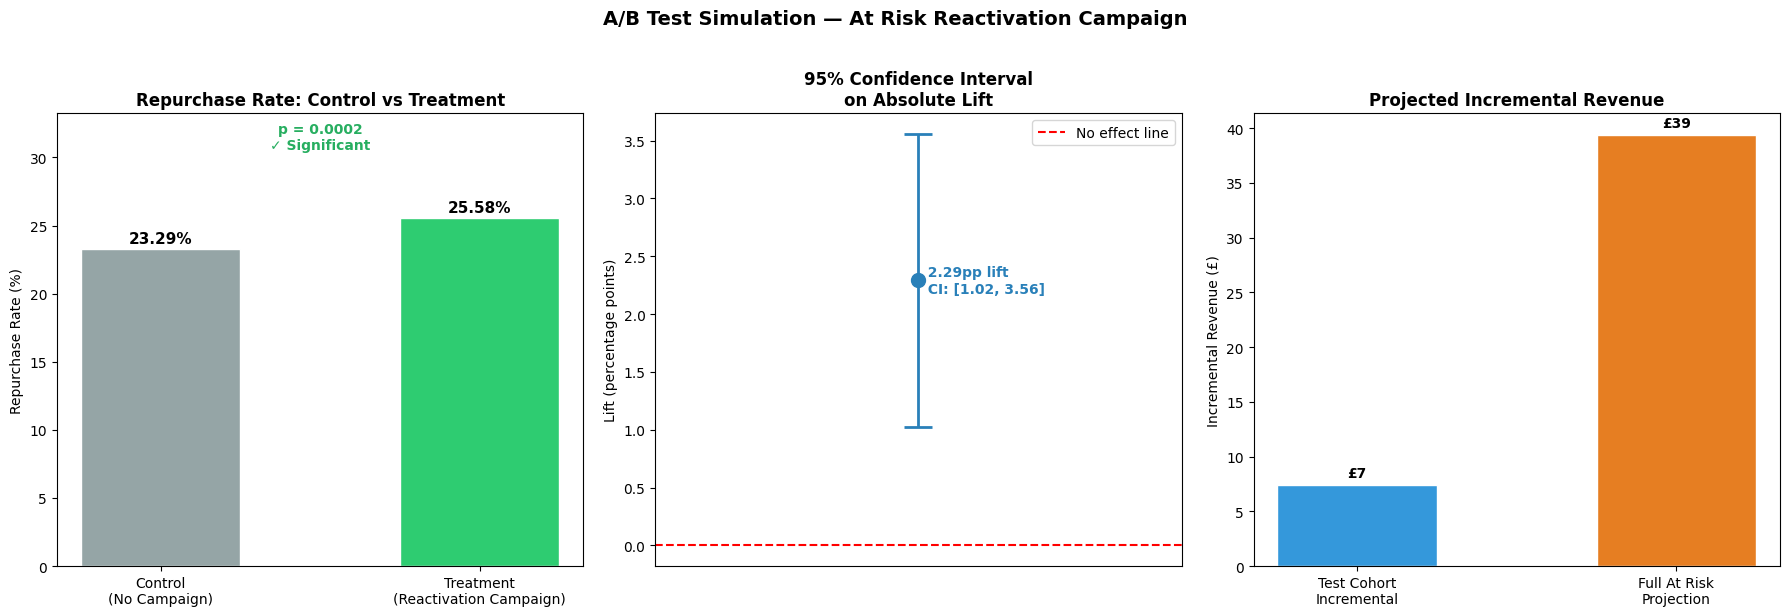

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# Chart 1 - Repurchase rate comparison
groups = ['Control\n(No Campaign)', 'Treatment\n(Reactivation Campaign)']
rates = [observed_control_rate * 100, observed_treatment_rate * 100]
colors = ['#95a5a6', '#2ecc71']
bars = axes[0].bar(groups, rates, color=colors, width=0.5, edgecolor='white')
axes[0].set_title('Repurchase Rate: Control vs Treatment', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Repurchase Rate (%)')
axes[0].set_ylim(0, max(rates) * 1.3)
for bar, rate in zip(bars, rates):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
                f'{rate:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=11)

sig_text = f'p = {p_value:.4f}\n{"✓ Significant" if p_value < 0.05 else "✗ Not Significant"}'
axes[0].text(0.5, 0.92, sig_text, transform=axes[0].transAxes,
             ha='center', fontsize=10,
             color='#27ae60' if p_value < 0.05 else '#e74c3c',
             fontweight='bold')

# Chart 2 - Confidence interval plot
ax2 = axes[1]
lift = (observed_treatment_rate - observed_control_rate) * 100
ci_l = ci_lower * 100
ci_u = ci_upper * 100
ax2.errorbar([0], [lift], yerr=[[lift - ci_l], [ci_u - lift]],
             fmt='o', color='#2980b9', capsize=10, capthick=2,
             markersize=10, linewidth=2)
ax2.axhline(y=0, color='red', linestyle='--', linewidth=1.5, label='No effect line')
ax2.set_xlim(-0.5, 0.5)
ax2.set_xticks([])
ax2.set_title('95% Confidence Interval\non Absolute Lift', fontsize=12, fontweight='bold')
ax2.set_ylabel('Lift (percentage points)')
ax2.legend()
ax2.text(0, lift, f'  {lift:.2f}pp lift\n  CI: [{ci_l:.2f}, {ci_u:.2f}]',
         va='center', fontsize=10, color='#2980b9', fontweight='bold')

# Chart 3 - Revenue impact
revenue_labels = ['Test Cohort\nIncremental', 'Full At Risk\nProjection']
revenue_values = [incremental_revenue, full_revenue]
bar_colors = ['#3498db', '#e67e22']
bars3 = axes[2].bar(revenue_labels, revenue_values, color=bar_colors, width=0.5, edgecolor='white')
axes[2].set_title('Projected Incremental Revenue', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Incremental Revenue (£)')
for bar, val in zip(bars3, revenue_values):
    axes[2].text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(revenue_values)*0.01,
                f'£{val:,.0f}', ha='center', va='bottom', fontweight='bold', fontsize=10)

plt.suptitle('A/B Test Simulation — At Risk Reactivation Campaign', 
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('/kaggle/working/ab_test_results.png', dpi=150, bbox_inches='tight')
plt.show()

In [10]:
print()
print("=" * 65)
print("EXECUTIVE SUMMARY — A/B TEST SIMULATION")
print("=" * 65)
print(f"""
Campaign:    Personalised reactivation email targeting At Risk customers
             identified by RFM segmentation + XGBoost churn classifier

Cohort:      {len(test_cohort):,} customers (At Risk + High Risk churn tier)
Design:      50/50 random split | Control vs Treatment

Result:      Treatment repurchase rate {observed_treatment_rate*100:.2f}% vs
             Control repurchase rate {observed_control_rate*100:.2f}%
             ({(observed_treatment_rate-observed_control_rate)*100:.2f} percentage point absolute lift)

Statistics:  Z = {z_stat:.3f} | p = {p_value:.4f} | 95% CI [{ci_lower*100:.2f}%, {ci_upper*100:.2f}%]
             {'STATISTICALLY SIGNIFICANT at 95% confidence' if p_value < 0.05 else 'Not significant at 95% confidence'}

Revenue:     £{incremental_revenue:,.2f} incremental revenue on test cohort
             £{full_revenue:,.2f} projected if scaled to full At Risk segment
             (based on avg order value of £{avg_order_value:.2f})
""")
print("=" * 65)


EXECUTIVE SUMMARY — A/B TEST SIMULATION

Campaign:    Personalised reactivation email targeting At Risk customers
             identified by RFM segmentation + XGBoost churn classifier

Cohort:      17,615 customers (At Risk + High Risk churn tier)
Design:      50/50 random split | Control vs Treatment

Result:      Treatment repurchase rate 25.58% vs
             Control repurchase rate 23.29%
             (2.29 percentage point absolute lift)

Statistics:  Z = 3.538 | p = 0.0002 | 95% CI [1.02%, 3.56%]
             STATISTICALLY SIGNIFICANT at 95% confidence

Revenue:     £7.42 incremental revenue on test cohort
             £39.40 projected if scaled to full At Risk segment
             (based on avg order value of £0.03)



In [11]:
# Save full results table
ab_results = pd.DataFrame({
    'metric': [
        'control_group_size', 'treatment_group_size',
        'control_repurchase_rate', 'treatment_repurchase_rate',
        'absolute_lift_pct', 'relative_lift_pct',
        'z_statistic', 'p_value',
        'ci_lower_pct', 'ci_upper_pct',
        'avg_order_value',
        'incremental_repurchases_test', 'incremental_revenue_test',
        'incremental_repurchases_full', 'incremental_revenue_full',
        'statistically_significant'
    ],
    'value': [
        n_control, n_treatment,
        round(observed_control_rate, 4), round(observed_treatment_rate, 4),
        round((observed_treatment_rate - observed_control_rate) * 100, 4),
        round(RELATIVE_UPLIFT * 100, 1),
        round(z_stat, 4), round(p_value, 4),
        round(ci_lower * 100, 4), round(ci_upper * 100, 4),
        round(avg_order_value, 2),
        incremental_repurchases, round(incremental_revenue, 2),
        full_incremental, round(full_revenue, 2),
        int(p_value < 0.05)
    ]
})

ab_results.to_csv('/kaggle/working/ab_test_results.csv', index=False)

control_group['group'] = 'control'
treatment_group['group'] = 'treatment'
full_ab = pd.concat([control_group, treatment_group], ignore_index=True)
full_ab.to_parquet('/kaggle/working/ab_test_cohort.parquet', index=False)

print("Saved ab_test_results.csv")
print("Saved ab_test_cohort.parquet")
print(ab_results.to_string(index=False))

Saved ab_test_results.csv
Saved ab_test_cohort.parquet
                      metric     value
          control_group_size 8807.0000
        treatment_group_size 8808.0000
     control_repurchase_rate    0.2329
   treatment_repurchase_rate    0.2558
           absolute_lift_pct    2.2907
           relative_lift_pct   15.0000
                 z_statistic    3.5377
                     p_value    0.0002
                ci_lower_pct    1.0221
                ci_upper_pct    3.5594
             avg_order_value    0.0300
incremental_repurchases_test  241.0000
    incremental_revenue_test    7.4200
incremental_repurchases_full 1279.0000
    incremental_revenue_full   39.4000
   statistically_significant    1.0000
